# Experimentation & A/B Testing Intelligence Platform

## 1. Business Problem

E-commerce teams constantly run A/B tests (checkout redesigns, CTA changes, page layouts) and
need a rigorous, repeatable way to decide whether a variant actually performed better - not just
whether p < 0.05, but whether the effect is big enough to matter.

This notebook analyzes three synthetic experiments:
- **checkout_redesign** - a large, meaningful lift
- **cta_redesign** - a small, likely-noise effect
- **product_page_redesign** - a statistically significant lift that is too small to matter much
  practically (a classic "statistically significant but not practically significant" case)


In [1]:
import sys, os
sys.path.append(os.path.join(os.getcwd(), '..', 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

RAW_PATH = os.path.join('..', 'data', 'raw', 'ab_test_users.csv')
CLEAN_PATH = os.path.join('..', 'data', 'processed', 'ab_test_users_clean.csv')


## 2. Dataset

Synthetically generated (`src/generate_data.py`) with three experiments, each with a control/treatment split, realistic missing values, duplicate rows, **contaminated users** (appearing in both variants), and impossible values. If not already generated:

```bash
python src/generate_data.py
```

In [2]:
if not os.path.exists(RAW_PATH):
    raise FileNotFoundError("Run `python src/generate_data.py` from the project root first.")

raw_df = pd.read_csv(RAW_PATH)
print(f"Rows: {len(raw_df):,}   Experiments: {raw_df['experiment_id'].nunique()}")
raw_df.head()


Rows: 112,849   Experiments: 3


,experiment_id,user_id,experiment_date,variant,device,country_or_region,customer_type,sessions,purchases,revenue,conversion,average_order_value
0,product_page_redesign,PRO-U37528567,2023-08-21,treatment,mobile,North America,new,1,0,0.0,0,NaN
1,product_page_redesign,PRO-U20974464,2023-08-20,control,mobile,North America,new,1,0,0.0,0,NaN
2,checkout_redesign,CHE-U47549699,2023-03-12,control,mobile,Europe,returning,1,0,-1.0,0,NaN
3,checkout_redesign,CHE-U85269339,2023-03-11,control,mobile,Asia Pacific,new,1,0,0.0,0,NaN
4,product_page_redesign,PRO-U32254694,2023-08-25,control,mobile,Europe,new,1,0,0.0,0,NaN


## 3. Data Understanding

In [3]:
raw_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 112849 entries, 0 to 112848
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   experiment_id        112849 non-null  str    
 1   user_id              112849 non-null  str    
 2   experiment_date      112849 non-null  str    
 3   variant              112849 non-null  str    
 4   device               111687 non-null  str    
 5   country_or_region    111913 non-null  str    
 6   customer_type        112849 non-null  str    
 7   sessions             112849 non-null  int64  
 8   purchases            112849 non-null  int64  
 9   revenue              112503 non-null  float64
 10  conversion           112849 non-null  int64  
 11  average_order_value  10744 non-null   float64
dtypes: float64(2), int64(3), str(7)
memory usage: 10.3 MB


In [4]:
raw_df.groupby(['experiment_id','variant']).size().unstack()


variant,control,treatment
experiment_id,,
checkout_redesign,9029,9044
cta_redesign,2646,1766
product_page_redesign,45139,45225


## 4. Data Quality

We explicitly check for duplicates, contaminated users (present in both variants of the same experiment - this breaks the independence assumption behind our statistical tests), missing values, invalid assignments, impossible values, and sample balance.

In [5]:
from data_quality import run_all_checks, print_report

report, contaminated = run_all_checks(raw_df)
print_report(report)
print(f"\nExample contaminated users (first 5):")
display(contaminated.head())


DATA QUALITY REPORT
Total rows: 112,849
Exact duplicate rows: 318
Duplicate (user, variant) pairs: 368
Users contaminated across variants: 135
Invalid variant label rows: 0

Impossible values:
  - negative_revenue: 127
  - purchases_exceed_sessions: 80
  - negative_sessions: 0

Missing values by column:
  - device: 1162
  - country_or_region: 936
  - revenue: 346
  - average_order_value: 102105

Sample balance by experiment:
variant                control  treatment     ratio
experiment_id                                      
checkout_redesign         9029       9044  1.001661
cta_redesign              2646       1766  0.667423
product_page_redesign    45139      45225  1.001905

Example contaminated users (first 5):


,experiment_id,user_id,n_variants
2555,checkout_redesign,CHE-U22863236,2
2744,checkout_redesign,CHE-U23854945,2
2826,checkout_redesign,CHE-U24287245,2
3918,checkout_redesign,CHE-U29925374,2
4692,checkout_redesign,CHE-U33896046,2


## 5. Data Preprocessing

See `src/data_cleaning.py`. Contaminated users are **dropped entirely** from their experiment (we can't know which variant actually influenced them). Impossible values (negative revenue, purchases > sessions) are dropped, not guessed at.

In [6]:
from data_cleaning import clean

clean_df = clean(raw_df)
clean_df.to_csv(CLEAN_PATH, index=False)
clean_df.head()


Removed 318 exact duplicate rows.
Removed 270 rows from 135 contaminated users.
Removed 207 rows with impossible values.
Removed 36 converted rows missing revenue.
Rows after cleaning: 112,018 (from 112,849)


,experiment_id,user_id,experiment_date,variant,device,country_or_region,customer_type,sessions,purchases,revenue,conversion,average_order_value
0,product_page_redesign,PRO-U37528567,2023-08-21,treatment,mobile,North America,new,1,0,0.0,0,NaN
1,product_page_redesign,PRO-U20974464,2023-08-20,control,mobile,North America,new,1,0,0.0,0,NaN
2,checkout_redesign,CHE-U85269339,2023-03-11,control,mobile,Asia Pacific,new,1,0,0.0,0,NaN
3,product_page_redesign,PRO-U32254694,2023-08-25,control,mobile,Europe,new,1,0,0.0,0,NaN
4,product_page_redesign,PRO-U83501699,2023-08-06,control,desktop,Latin America,new,1,0,0.0,0,NaN


## 6. EDA

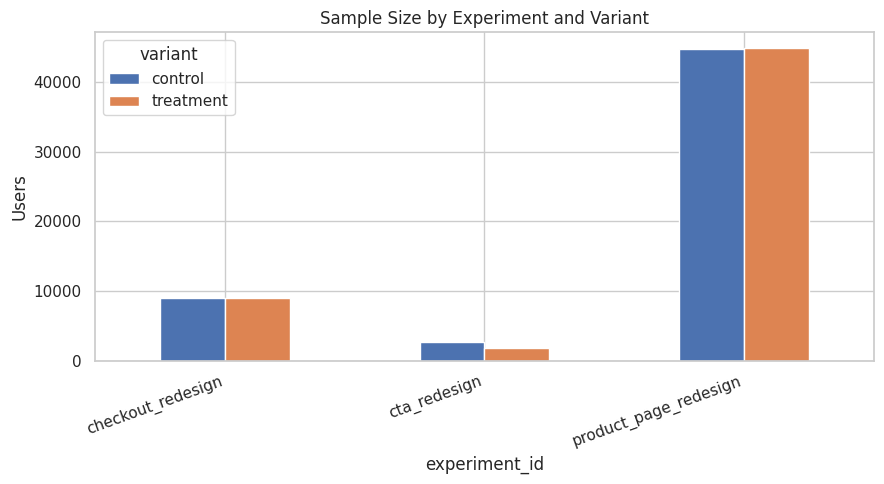

In [7]:
counts = clean_df.groupby(['experiment_id','variant']).size().unstack()
fig, ax = plt.subplots(figsize=(9,5))
counts.plot(kind='bar', ax=ax)
ax.set_ylabel('Users')
ax.set_title('Sample Size by Experiment and Variant')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()


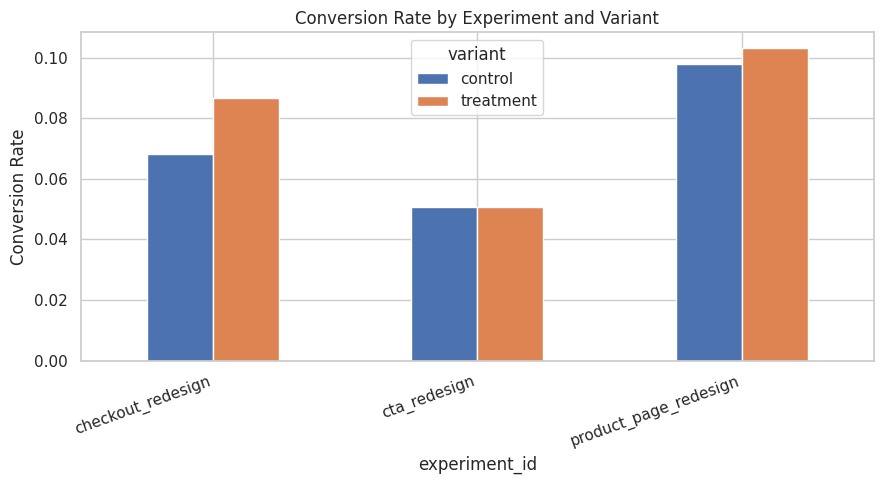

variant,control,treatment
experiment_id,,
checkout_redesign,0.068139,0.086541
cta_redesign,0.050590,0.050626
product_page_redesign,0.097847,0.103186


In [8]:
conv = clean_df.groupby(['experiment_id','variant'])['conversion'].mean().unstack()
fig, ax = plt.subplots(figsize=(9,5))
conv.plot(kind='bar', ax=ax)
ax.set_ylabel('Conversion Rate')
ax.set_title('Conversion Rate by Experiment and Variant')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()
display(conv)


**Observation:** `checkout_redesign` shows a visually obvious gap between variants; `cta_redesign` shows almost no difference; `product_page_redesign` shows a small but visible gap. We now quantify each with a formal statistical test rather than relying on the chart alone.

## 7. Statistical Testing

**Null hypothesis (H0):** treatment conversion rate = control conversion rate.
**Alternative hypothesis (H1):** treatment conversion rate != control conversion rate.

We use a two-proportion z-test for conversion (`statsmodels.stats.proportion.proportions_ztest`) and report the absolute difference, relative difference, a 95% confidence interval, the p-value, and Cohen's h as an effect size - **and we always pair the statistical result with a practical-significance judgment**, never just "p < 0.05 means treatment won."

In [9]:
from ab_test_analysis import run_all_experiments, run_all_revenue, print_conversion_results

conv_results = run_all_experiments(clean_df)
rev_results = run_all_revenue(clean_df)

print_conversion_results(conv_results)


Experiment: checkout_redesign
  Control:   n=8,967   conversion=0.0681
  Treatment: n=8,990   conversion=0.0865
  Absolute diff: 0.0184   Relative diff: 27.01%
  95% CI (absolute diff): [0.0106, 0.0262]
  z = 4.615   p = 3.926e-06   Cohen's h = 0.0690
  Statistically significant: True   Practically significant: True
  Interpretation: Statistically significant AND practically meaningful: the observed lift is unlikely to be due to chance and is large enough to matter for the business.
Experiment: cta_redesign
  Control:   n=2,629   conversion=0.0506
  Treatment: n=1,758   conversion=0.0506
  Absolute diff: 0.0000   Relative diff: 0.07%
  95% CI (absolute diff): [-0.0132, 0.0133]
  z = 0.005   p = 0.99573   Cohen's h = 0.0002
  Statistically significant: False   Practically significant: False
  Interpretation: Neither statistically nor practically significant: no reliable evidence of a difference between variants.
Experiment: product_page_redesign
  Control:   n=44,784   conversion=0.0979

In [10]:
print("Revenue-per-user results (independent two-sample t-test):")
rev_results


Revenue-per-user results (independent two-sample t-test):


,experiment_id,metric,mean_control,mean_treatment,absolute_difference,relative_difference_pct,t_statistic,p_value,statistically_significant
0,checkout_redesign,revenue_per_user,4.30,5.58,1.28,29.79,4.822,0.000001,True
1,cta_redesign,revenue_per_user,2.24,2.42,0.17,7.76,0.528,0.597615,False
2,product_page_redesign,revenue_per_user,5.36,5.66,0.30,5.58,2.595,0.009464,True


## 8. Statistical vs. Practical Significance - Worked Comparison

This is the central methodological point of this project.

In [11]:
display_cols = ['experiment_id','control_rate','treatment_rate','relative_difference_pct',
                'p_value','statistically_significant','practically_significant']
conv_results[display_cols]


,experiment_id,control_rate,treatment_rate,relative_difference_pct,p_value,statistically_significant,practically_significant
0,checkout_redesign,0.06814,0.08654,27.01,0.000004,True,True
1,cta_redesign,0.05059,0.05063,0.07,0.995731,False,False
2,product_page_redesign,0.09785,0.10319,5.46,0.007858,True,False


**Reading the table above:**
- **`checkout_redesign`**: large relative lift, tiny p-value -> statistically AND practically significant. Ship it.
- **`cta_redesign`**: near-zero relative difference, large p-value -> no evidence of any effect. Do not ship based on this result; consider a bigger, better-targeted test if there's still a reason to believe the CTA change should matter.
- **`product_page_redesign`**: the p-value is well below 0.05 (thanks to a very large sample size), but the relative lift is below our documented practical-significance threshold. **This is the key lesson: with enough users, even a tiny, low-impact difference becomes "statistically significant." A p-value alone never tells you whether an effect is worth acting on.**

## 9. Segment Analysis (Exploratory)

We break down each experiment's conversion results by device, region, and customer type. **This section is explicitly exploratory**: running many segment cuts is a multiple-comparisons problem - some cuts will look 'significant' by chance alone, especially in smaller segments. We flag low-sample segments and do not apply a formal correction, but we print an explicit warning and treat any 'significant' subgroup finding as a hypothesis to confirm in a dedicated follow-up test, not a standalone conclusion.

In [12]:
from segment_analysis import full_segment_report, MIN_SEGMENT_N

segment_report = full_segment_report(clean_df)

n_tests = len(segment_report)
n_sig = segment_report['significant_uncorrected'].sum()
print(f"Ran {n_tests} exploratory segment cuts; {n_sig} came back 'significant' at p<0.05 "
      f"WITHOUT multiple-comparisons correction - some of these are expected to be false "
      f"positives purely from running many tests.")

segment_report[segment_report['experiment_id'] == 'checkout_redesign']


Ran 33 exploratory segment cuts; 10 came back 'significant' at p<0.05 WITHOUT multiple-comparisons correction - some of these are expected to be false positives purely from running many tests.


,experiment_id,segment_type,segment_value,n_control,n_treatment,control_rate,treatment_rate,relative_diff_pct,p_value,significant_uncorrected,low_sample_warning
0,checkout_redesign,device,Unknown,93,102,0.0968,0.0882,-8.82,0.836987,False,True
1,checkout_redesign,device,desktop,4077,4043,0.0652,0.0890,36.48,0.000058,True,False
2,checkout_redesign,device,mobile,3924,3956,0.0691,0.0854,23.71,0.006487,True,False
3,checkout_redesign,device,tablet,873,889,0.0745,0.0799,7.26,0.670574,False,False
4,checkout_redesign,country_or_region,Asia Pacific,2181,2293,0.0637,0.0824,29.33,0.016498,True,False
5,checkout_redesign,country_or_region,Europe,2718,2674,0.0699,0.0823,17.69,0.086656,False,False
6,checkout_redesign,country_or_region,Latin America,867,895,0.0611,0.0994,62.67,0.003141,True,False
7,checkout_redesign,country_or_region,North America,3128,3051,0.0719,0.0898,24.85,0.009926,True,False
8,checkout_redesign,country_or_region,Unknown,73,77,0.0548,0.0779,42.21,0.570328,False,True
9,checkout_redesign,customer_type,new,4937,4993,0.0674,0.0877,30.06,0.000160,True,False


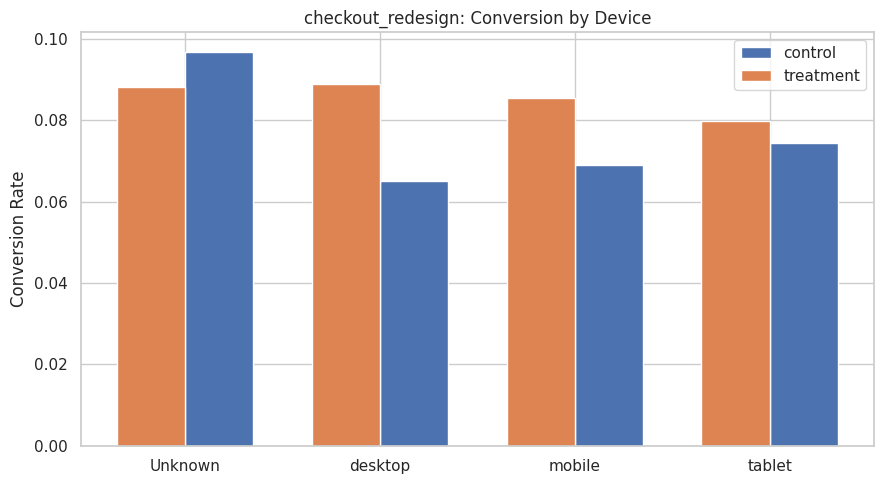

In [13]:
fig, ax = plt.subplots(figsize=(9,5))
cr = segment_report[(segment_report['experiment_id']=='checkout_redesign') & (segment_report['segment_type']=='device')]
ax.bar(cr['segment_value'], cr['control_rate'], width=0.35, label='control', align='edge')
ax.bar(cr['segment_value'], cr['treatment_rate'], width=-0.35, label='treatment', align='edge')
ax.set_ylabel('Conversion Rate')
ax.set_title('checkout_redesign: Conversion by Device')
ax.legend()
plt.tight_layout()
plt.show()


## 10. Optional Experiment Simulator (Sample Size & Power)

An educational tool: given a baseline rate and a minimum detectable effect, how many users per arm do you need? And empirically, via Monte Carlo simulation, how does statistical power actually grow with sample size?

In [14]:
from experiment_simulator import sample_size_table, simulate_power_curve

print("Required sample size per arm to detect various relative lifts")
print("(baseline = 8% conversion, alpha=0.05, power=0.80):\n")
table = sample_size_table(baseline_rate=0.08)
display(table)


Required sample size per arm to detect various relative lifts
(baseline = 8% conversion, alpha=0.05, power=0.80):



,baseline_rate,relative_effect,target_rate,required_n_per_arm,alpha,power
0,0.08,0.02,0.0816,455416,0.05,0.8
1,0.08,0.05,0.0840,73844,0.05,0.8
2,0.08,0.10,0.0880,18863,0.05,0.8
3,0.08,0.20,0.0960,4912,0.05,0.8
4,0.08,0.30,0.1040,2268,0.05,0.8


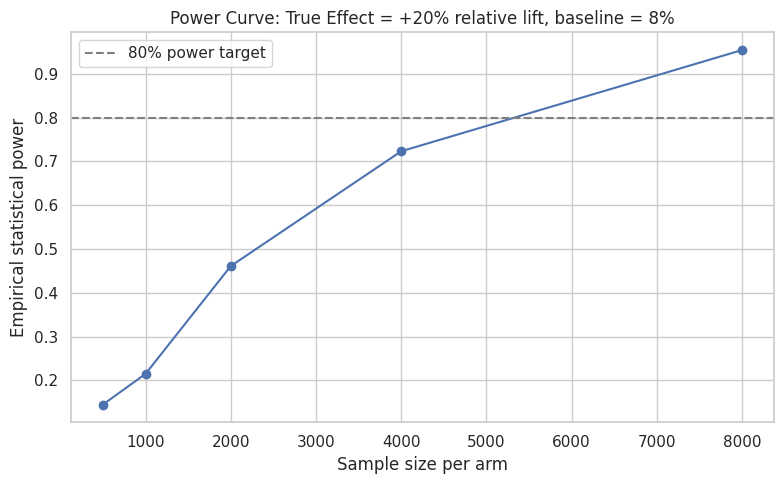

,n_per_arm,empirical_power
0,500,0.145
1,1000,0.215
2,2000,0.461
3,4000,0.723
4,8000,0.954


In [15]:
power_curve = simulate_power_curve(
    baseline_rate=0.08, true_relative_effect=0.20,
    sample_sizes=[500, 1000, 2000, 4000, 8000], n_simulations=800,
)

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(power_curve['n_per_arm'], power_curve['empirical_power'], marker='o')
ax.axhline(0.8, color='gray', linestyle='--', label='80% power target')
ax.set_xlabel('Sample size per arm')
ax.set_ylabel('Empirical statistical power')
ax.set_title('Power Curve: True Effect = +20% relative lift, baseline = 8%')
ax.legend()
plt.tight_layout()
plt.show()
display(power_curve)


**Interpretation:** with too few users per arm, even a real 20% relative lift is often missed ("underpowered" test, high false-negative risk). Power climbs toward 80% as sample size increases, matching the analytic sample-size table above.

## 11. Findings, Limitations & Conclusion

**Key findings:**
1. `checkout_redesign` shows a large, statistically robust, practically meaningful conversion lift - the clearest candidate to ship.
2. `cta_redesign` shows no reliable evidence of an effect; more data or a more impactful variant would be needed before concluding anything.
3. `product_page_redesign` is a textbook illustration of statistical significance without clear practical significance - a reminder to always report effect size and a practical-significance judgment alongside the p-value.
4. Segment-level results should be treated as exploratory/hypothesis-generating given the multiple-comparisons risk and, in some cuts, small sample sizes.

**Limitations:**
- Synthetic data: absolute effect sizes are illustrative; the methodology transfers, not the specific numbers.
- Each user is modeled with a single exposure/session in this simplified dataset; a real experimentation platform would need to handle multiple sessions per user and time-to-convert.
- The practical-significance threshold (documented in `ab_test_analysis.py`) is a business-configurable assumption, not a statistical fact.
- No multiple-comparisons correction was applied to the segment analysis; treat those results as exploratory only.

**Conclusion:** This notebook demonstrates a complete, defensible experimentation workflow: data-quality checks tailored to A/B testing pitfalls (contamination, imbalance), properly specified hypothesis tests, an explicit statistical-vs-practical-significance framework, cautious subgroup analysis, and an educational power/sample-size simulator. See `README.md` for dashboard instructions and interview questions.